In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn  as sns 
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
from sklearn.linear_model  import LogisticRegression 
from sklearn.semi_supervised  import SelfTrainingClassifier 
from sklearn.model_selection  import train_test_split 
from sklearn.datasets  import  make_classification

In [2]:
X,y =  make_classification(
    n_classes=2,
    n_features=3,
    n_samples= 100,
    n_informative= 3,
    n_redundant= 0,
    class_sep=1.5
)

In [4]:
df =  pd.DataFrame(X,columns=['cgpa','attendance','study_hours'])
df['target'] = y 


x_train, x_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [5]:
# now picking small part  
np.random.seed(42)

y_semi = y_train.copy()

unlabelled_indices =  np.random.choice(
    len(y_semi),
    size = 60,
    replace= False

)

y_semi[unlabelled_indices] = -1

print("label",np.sum(y_semi != -1))
print("unlabelled",np.sum(y_semi == -1))


label 20
unlabelled 60


In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

initial_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(random_state=42)
)

# Train only on the 20 labelled records
initial_model.fit(
    x_train[y_semi != -1],
    y_semi[y_semi != -1]
)

print("Initial Logistic Regression trained!")

Initial Logistic Regression trained!


In [7]:
self_model =  SelfTrainingClassifier(
    estimator = make_pipeline(StandardScaler(),LogisticRegression(random_state=42)),
    threshold= 0.80,
    criterion= 'threshold',
    max_iter= 10
)


In [9]:

self_model.fit(x_train,y_semi)

,estimator,Pipeline(step...m_state=42))])
,base_estimator,'deprecated'
,threshold,0.8
,criterion,'threshold'
,k_best,10
,max_iter,10
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,penalty,'l2'


In [10]:
print("intially labeled : ",np.sum(y_semi !=  -1))
print("unlabelled : ",np,sum(self_model.transduction_[y_semi == -1] != -1))



intially labeled :  20
unlabelled :  <module 'numpy' from 'd:\\understanding-RAG\\.venv\\lib\\site-packages\\numpy\\__init__.py'> 50


In [11]:
y_pred = self_model.predict(x_test)

print("Actual:", y_test)
print("Predicted:", y_pred)

Actual: [1 1 1 1 0 0 0 1 0 0 0 1 0 0 0 1 1 0 1 1]
Predicted: [1 1 1 1 0 0 0 1 0 0 0 1 0 1 0 0 1 0 1 1]


Self-Training Accuracy: 90.0 %


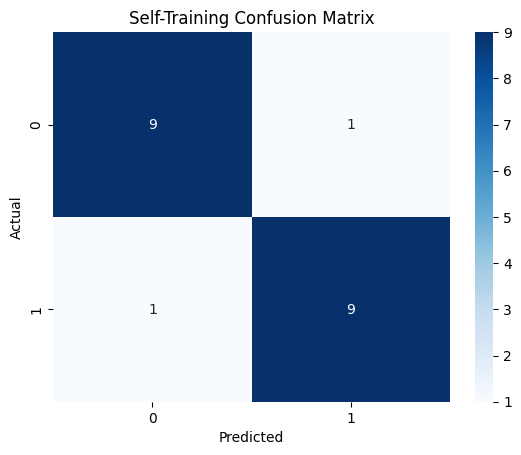

In [12]:
accuracy = accuracy_score(y_test, y_pred)

print("Self-Training Accuracy:", accuracy * 100, "%")

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Self-Training Confusion Matrix")

plt.show()